# Problema 2

## 1)Carregar os Dados
Neste exemplo, vamos usar duas tabelas: uma com as temperaturas médias globais e outra com as temperaturas médias por continente.


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import requests
import zipfile
import io

In [ ]:
pd.set_option('display.max_columns', 79)

In [ ]:
# URL dos dados de temperaturas globais
url_global_temp = "https://raw.githubusercontent.com/owid/co2-data/master/owid-co2-data.csv"
url_continental_temp = "https://raw.githubusercontent.com/datasets/global-temp/master/data/monthly.csv"

# Carregar os dados
df_global_temp = pd.read_csv(url_global_temp)
df_continental_temp = pd.read_csv(url_continental_temp)

print("DataFrame de Temperatura Global:")
print(df_global_temp[['year', 'co2']].head())
print("\nDataFrame de Temperatura Continental:")
print(df_continental_temp.head())

DataFrame de Temperatura Global:
   year  co2
0  1750  NaN
1  1751  NaN
2  1752  NaN
3  1753  NaN
4  1754  NaN

DataFrame de Temperatura Continental:
  Source     Year    Mean
0   GCAG  1850-01 -0.7337
1   GCAG  1850-02 -0.3604
2   GCAG  1850-03 -0.6271
3   GCAG  1850-04 -0.6053
4   GCAG  1850-05 -0.5315


Repositório e fonte do df_continental_temp:
- https://github.com/datasets/global-temp
- https://datahub.io/core/global-temp

In [ ]:
schema_df_continental_temp = pd.DataFrame({
    'Field' : ['Source', 'Year', 'Mean'],
    'Type' : ['string', 'date', 'number'],
    'Format' : ['' , 'any', ''],
    'Description' : ['Data provider identifier: GISTEMP (NASA Goddard Institute for Space Studies) or GCAG (UK Met Office HadCRUT5).',
                     'YYYY-MM', 'Monthly mean temperature anomalies in degrees Celsius relative to a base period. GISTEMP base period: 1951-1980. GCAG base period: 20th century average.']

})

schema_df_continental_temp.set_index('Field', inplace=True)
schema_df_continental_temp

,Type,Format,Description
Field,,,
Source,string,,Data provider identifier: GISTEMP (NASA Goddar...
Year,date,any,YYYY-MM
Mean,number,,Monthly mean temperature anomalies in degrees ...


Encontrei o repositório oficial completo do df_global_temp no GitHub: https://github.com/owid/co2-data

In [ ]:
# URL do codebook do df_global_temp (Dicionário de Dados)
url_codebook = "https://raw.githubusercontent.com/owid/co2-data/refs/heads/master/owid-co2-codebook.csv"

data_dictionary = pd.read_csv(url_codebook, index_col='column')

data_dictionary.head()

,title,description,unit,source
column,,,,
country,Country,Geographic location.,NaN,Our World in Data - Regions (2024)
year,Year,Year of observation.,NaN,Our World in Data - Regions (2024)
iso_code,ISO code,ISO 3166-1 alpha-3 three-letter country codes.,NaN,International Organization for Standardization...
population,Population,"Population by country, available from 10,000 B...",people,Population based on various sources (2024) [ht...
gdp,Gross domestic product (GDP),Total economic output of a country or region p...,international-$ in 2011 prices ($),Bolt and van Zanden – Maddison Project Databas...


In [ ]:
data_dictionary.index

Index(['country', 'year', 'iso_code', 'population', 'gdp', 'cement_co2',
       'cement_co2_per_capita', 'co2', 'co2_growth_abs', 'co2_growth_prct',
       'co2_including_luc', 'co2_including_luc_growth_abs',
       'co2_including_luc_growth_prct', 'co2_including_luc_per_capita',
       'co2_including_luc_per_gdp', 'co2_including_luc_per_unit_energy',
       'co2_per_capita', 'co2_per_gdp', 'co2_per_unit_energy', 'coal_co2',
       'coal_co2_per_capita', 'consumption_co2', 'consumption_co2_per_capita',
       'consumption_co2_per_gdp', 'cumulative_cement_co2', 'cumulative_co2',
       'cumulative_co2_including_luc', 'cumulative_coal_co2',
       'cumulative_flaring_co2', 'cumulative_gas_co2', 'cumulative_luc_co2',
       'cumulative_oil_co2', 'cumulative_other_co2', 'energy_per_capita',
       'energy_per_gdp', 'flaring_co2', 'flaring_co2_per_capita', 'gas_co2',
       'gas_co2_per_capita', 'ghg_excluding_lucf_per_capita', 'ghg_per_capita',
       'land_use_change_co2', 'land_use_chang

## AED + Preparação dos Dados para a junção

In [ ]:
df_global_temp.head()

,country,year,iso_code,population,gdp,cement_co2,cement_co2_per_capita,co2,co2_growth_abs,co2_growth_prct,co2_including_luc,co2_including_luc_growth_abs,co2_including_luc_growth_prct,co2_including_luc_per_capita,co2_including_luc_per_gdp,co2_including_luc_per_unit_energy,co2_per_capita,co2_per_gdp,co2_per_unit_energy,coal_co2,coal_co2_per_capita,consumption_co2,consumption_co2_per_capita,consumption_co2_per_gdp,cumulative_cement_co2,cumulative_co2,cumulative_co2_including_luc,cumulative_coal_co2,cumulative_flaring_co2,cumulative_gas_co2,cumulative_luc_co2,cumulative_oil_co2,cumulative_other_co2,energy_per_capita,energy_per_gdp,flaring_co2,flaring_co2_per_capita,gas_co2,gas_co2_per_capita,ghg_excluding_lucf_per_capita,ghg_per_capita,land_use_change_co2,land_use_change_co2_per_capita,methane,methane_per_capita,nitrous_oxide,nitrous_oxide_per_capita,oil_co2,oil_co2_per_capita,other_co2_per_capita,other_industry_co2,primary_energy_consumption,share_global_cement_co2,share_global_co2,share_global_co2_including_luc,share_global_coal_co2,share_global_cumulative_cement_co2,share_global_cumulative_co2,share_global_cumulative_co2_including_luc,share_global_cumulative_coal_co2,share_global_cumulative_flaring_co2,share_global_cumulative_gas_co2,share_global_cumulative_luc_co2,share_global_cumulative_oil_co2,share_global_cumulative_other_co2,share_global_flaring_co2,share_global_gas_co2,share_global_luc_co2,share_global_oil_co2,share_global_other_co2,share_of_temperature_change_from_ghg,temperature_change_from_ch4,temperature_change_from_co2,temperature_change_from_ghg,temperature_change_from_n2o,total_ghg,total_ghg_excluding_lucf,trade_co2,trade_co2_share
0,Afghanistan,1750,AFG,2802560.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Afghanistan,1751,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,1752,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,1753,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,1754,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df_global_temp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50411 entries, 0 to 50410
Data columns (total 79 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   country                                    50411 non-null  object 
 1   year                                       50411 non-null  int64  
 2   iso_code                                   42480 non-null  object 
 3   population                                 41167 non-null  float64
 4   gdp                                        15251 non-null  float64
 5   cement_co2                                 29173 non-null  float64
 6   cement_co2_per_capita                      25648 non-null  float64
 7   co2                                        29384 non-null  float64
 8   co2_growth_abs                             27216 non-null  float64
 9   co2_growth_prct                            26239 non-null  float64
 10  co2_including_luc     

In [ ]:
df_global_temp.duplicated().sum()
# nenhuma linha duplicada

np.int64(0)

In [ ]:
df_global_temp.isnull().sum()
# temos MUITOS valores ausentes!

,0
country,0
year,0
iso_code,7931
population,9244
gdp,35160
...,...
temperature_change_from_n2o,12131
total_ghg,12261
total_ghg_excluding_lucf,12598
trade_co2,45699


Limpeza dos dados do DataFrame df_global_temp:

In [ ]:
df_global_temp.shape

(50411, 79)

In [ ]:
critical_value = 0.65 * 50411

print(critical_value)
# qualquer coluna com mais valores ausentes que isso devem ser removidas imediatamente! (mais de 65% de valores faltando)

32767.15


In [ ]:
df_global_temp_nulls = df_global_temp.isnull().sum()

filt_critical_columns = df_global_temp_nulls >= critical_value

print('Colunas que devem ser imediatamente REMOVIDAS!')
df_global_temp_nulls.loc[filt_critical_columns]

Colunas que devem ser imediatamente REMOVIDAS!


,0
gdp,35160
co2_including_luc_per_gdp,33621
co2_including_luc_per_unit_energy,40278
co2_per_gdp,32883
co2_per_unit_energy,39585
consumption_co2,45358
consumption_co2_per_capita,45768
consumption_co2_per_gdp,45963
cumulative_flaring_co2,34300
cumulative_other_co2,47157


In [ ]:
df_global_temp_nulls.loc[filt_critical_columns].index

Index(['gdp', 'co2_including_luc_per_gdp', 'co2_including_luc_per_unit_energy',
       'co2_per_gdp', 'co2_per_unit_energy', 'consumption_co2',
       'consumption_co2_per_capita', 'consumption_co2_per_gdp',
       'cumulative_flaring_co2', 'cumulative_other_co2', 'energy_per_capita',
       'energy_per_gdp', 'flaring_co2', 'flaring_co2_per_capita',
       'gas_co2_per_capita', 'other_co2_per_capita', 'other_industry_co2',
       'primary_energy_consumption', 'share_global_cumulative_flaring_co2',
       'share_global_cumulative_gas_co2', 'share_global_cumulative_other_co2',
       'share_global_flaring_co2', 'share_global_gas_co2',
       'share_global_other_co2', 'trade_co2', 'trade_co2_share'],
      dtype='object')

In [ ]:
df_global_temp_cleaned = df_global_temp.drop(columns=['gdp', 'co2_including_luc_per_gdp', 'co2_including_luc_per_unit_energy',
       'co2_per_gdp', 'co2_per_unit_energy', 'consumption_co2',
       'consumption_co2_per_capita', 'consumption_co2_per_gdp',
       'cumulative_flaring_co2', 'cumulative_other_co2', 'energy_per_capita',
       'energy_per_gdp', 'flaring_co2', 'flaring_co2_per_capita',
       'gas_co2_per_capita', 'other_co2_per_capita', 'other_industry_co2',
       'primary_energy_consumption', 'share_global_cumulative_flaring_co2',
       'share_global_cumulative_gas_co2', 'share_global_cumulative_other_co2',
       'share_global_flaring_co2', 'share_global_gas_co2',
       'share_global_other_co2', 'trade_co2', 'trade_co2_share'])

df_global_temp_cleaned.shape
# agora o DataFrame tem 53 colunas

(50411, 53)

In [ ]:
df_global_temp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50411 entries, 0 to 50410
Data columns (total 79 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   country                                    50411 non-null  object 
 1   year                                       50411 non-null  int64  
 2   iso_code                                   42480 non-null  object 
 3   population                                 41167 non-null  float64
 4   gdp                                        15251 non-null  float64
 5   cement_co2                                 29173 non-null  float64
 6   cement_co2_per_capita                      25648 non-null  float64
 7   co2                                        29384 non-null  float64
 8   co2_growth_abs                             27216 non-null  float64
 9   co2_growth_prct                            26239 non-null  float64
 10  co2_including_luc     

In [ ]:
df_continental_temp.info()
# o valor 'Year' está como object, o que não faz sentido!!!
# vendo no head, já notei que preciso separar o ano e o mes com o hifen!

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3871 entries, 0 to 3870
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Source  3871 non-null   object 
 1   Year    3871 non-null   object 
 2   Mean    3871 non-null   float64
dtypes: float64(1), object(2)
memory usage: 90.9+ KB


In [ ]:
df_continental_temp.isnull().sum()
# nenhum valor nulo!

,0
Source,0
Year,0
Mean,0


In [ ]:
df_continental_temp.duplicated().sum()
# nenhuma linha duplicada!

np.int64(0)

In [ ]:
df_continental_temp.head()

,Source,Year,Mean
0,GCAG,1850-01,-0.7337
1,GCAG,1850-02,-0.3604
2,GCAG,1850-03,-0.6271
3,GCAG,1850-04,-0.6053
4,GCAG,1850-05,-0.5315


In [ ]:
df_global_temp['year'].value_counts()

,count
year,
2024,254
2023,254
2007,254
2006,254
2005,254
...,...
1780,58
1781,58
1782,58


In [ ]:
df_continental_temp['Year'].head(30)

,Year
0,1850-01
1,1850-02
2,1850-03
3,1850-04
4,1850-05
5,1850-06
6,1850-07
7,1850-08
8,1850-09
9,1850-10


In [ ]:
# criando colunas separadas para o ano e o mes do DataFrame df_continental_temp

df_continental_temp[['Year', 'Month']] = df_continental_temp['Year'].str.split('-', expand=True)

df_continental_temp[['Year', 'Month']].head(10)

,Year,Month
0,1850,01
1,1850,02
2,1850,03
3,1850,04
4,1850,05
5,1850,06
6,1850,07
7,1850,08
8,1850,09
9,1850,10


In [ ]:
df_continental_temp.head()
# agora as colunas estão corretas!

,Source,Year,Mean,Month
0,GCAG,1850,-0.7337,01
1,GCAG,1850,-0.3604,02
2,GCAG,1850,-0.6271,03
3,GCAG,1850,-0.6053,04
4,GCAG,1850,-0.5315,05


In [ ]:
# convertendo ano e mes para INT
df_continental_temp[['Year', 'Month']] = df_continental_temp[['Year', 'Month']].astype(int)
df_continental_temp.head()

,Source,Year,Mean,Month
0,GCAG,1850,-0.7337,1
1,GCAG,1850,-0.3604,2
2,GCAG,1850,-0.6271,3
3,GCAG,1850,-0.6053,4
4,GCAG,1850,-0.5315,5


In [ ]:
# passando os nomes das colunas para lower case
df_continental_temp.columns = df_continental_temp.columns.str.lower()
df_continental_temp.head()

,source,year,mean,month
0,GCAG,1850,-0.7337,1
1,GCAG,1850,-0.3604,2
2,GCAG,1850,-0.6271,3
3,GCAG,1850,-0.6053,4
4,GCAG,1850,-0.5315,5


In [ ]:
# garantindo que tudo estara ordenado pelo ano e pelo mes tambem
df_continental_temp = df_continental_temp.sort_values(by=['year', 'month'], ascending=True)
df_continental_temp[['year', 'month']].head(13)

,year,month
0,1850,1
1,1850,2
2,1850,3
3,1850,4
4,1850,5
5,1850,6
6,1850,7
7,1850,8
8,1850,9
9,1850,10


In [ ]:
# garantindo que estara ordenado pelo ano e pelo país tambem
df_global_temp = df_global_temp.sort_values(by=['year', 'country'], ascending=True)

df_global_temp.head(10)

,country,year,iso_code,population,gdp,cement_co2,cement_co2_per_capita,co2,co2_growth_abs,co2_growth_prct,co2_including_luc,co2_including_luc_growth_abs,co2_including_luc_growth_prct,co2_including_luc_per_capita,co2_including_luc_per_gdp,co2_including_luc_per_unit_energy,co2_per_capita,co2_per_gdp,co2_per_unit_energy,coal_co2,coal_co2_per_capita,consumption_co2,consumption_co2_per_capita,consumption_co2_per_gdp,cumulative_cement_co2,cumulative_co2,cumulative_co2_including_luc,cumulative_coal_co2,cumulative_flaring_co2,cumulative_gas_co2,cumulative_luc_co2,cumulative_oil_co2,cumulative_other_co2,energy_per_capita,energy_per_gdp,flaring_co2,flaring_co2_per_capita,gas_co2,gas_co2_per_capita,ghg_excluding_lucf_per_capita,ghg_per_capita,land_use_change_co2,land_use_change_co2_per_capita,methane,methane_per_capita,nitrous_oxide,nitrous_oxide_per_capita,oil_co2,oil_co2_per_capita,other_co2_per_capita,other_industry_co2,primary_energy_consumption,share_global_cement_co2,share_global_co2,share_global_co2_including_luc,share_global_coal_co2,share_global_cumulative_cement_co2,share_global_cumulative_co2,share_global_cumulative_co2_including_luc,share_global_cumulative_coal_co2,share_global_cumulative_flaring_co2,share_global_cumulative_gas_co2,share_global_cumulative_luc_co2,share_global_cumulative_oil_co2,share_global_cumulative_other_co2,share_global_flaring_co2,share_global_gas_co2,share_global_luc_co2,share_global_oil_co2,share_global_other_co2,share_of_temperature_change_from_ghg,temperature_change_from_ch4,temperature_change_from_co2,temperature_change_from_ghg,temperature_change_from_n2o,total_ghg,total_ghg_excluding_lucf,trade_co2,trade_co2_share
0,Afghanistan,1750,AFG,2802560.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
275,Africa,1750,NaN,79382032.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1075,Andorra,1750,AND,2221.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1700,Antarctica,1750,ATA,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2679,Asia,1750,NaN,498699232.0,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3129,Asia (excl. China and India),1750,NaN,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3404,Australia,1750,AUS,314500.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,0.0,0.0,NaN,0.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN

In [ ]:
# resetando o indice do DataFrame pra ficar ordenado e dropando os indices originais
df_global_temp_reset_drop = df_global_temp.reset_index(drop=True)
df_global_temp_reset_drop.head()

,country,year,iso_code,population,gdp,cement_co2,cement_co2_per_capita,co2,co2_growth_abs,co2_growth_prct,co2_including_luc,co2_including_luc_growth_abs,co2_including_luc_growth_prct,co2_including_luc_per_capita,co2_including_luc_per_gdp,co2_including_luc_per_unit_energy,co2_per_capita,co2_per_gdp,co2_per_unit_energy,coal_co2,coal_co2_per_capita,consumption_co2,consumption_co2_per_capita,consumption_co2_per_gdp,cumulative_cement_co2,cumulative_co2,cumulative_co2_including_luc,cumulative_coal_co2,cumulative_flaring_co2,cumulative_gas_co2,cumulative_luc_co2,cumulative_oil_co2,cumulative_other_co2,energy_per_capita,energy_per_gdp,flaring_co2,flaring_co2_per_capita,gas_co2,gas_co2_per_capita,ghg_excluding_lucf_per_capita,ghg_per_capita,land_use_change_co2,land_use_change_co2_per_capita,methane,methane_per_capita,nitrous_oxide,nitrous_oxide_per_capita,oil_co2,oil_co2_per_capita,other_co2_per_capita,other_industry_co2,primary_energy_consumption,share_global_cement_co2,share_global_co2,share_global_co2_including_luc,share_global_coal_co2,share_global_cumulative_cement_co2,share_global_cumulative_co2,share_global_cumulative_co2_including_luc,share_global_cumulative_coal_co2,share_global_cumulative_flaring_co2,share_global_cumulative_gas_co2,share_global_cumulative_luc_co2,share_global_cumulative_oil_co2,share_global_cumulative_other_co2,share_global_flaring_co2,share_global_gas_co2,share_global_luc_co2,share_global_oil_co2,share_global_other_co2,share_of_temperature_change_from_ghg,temperature_change_from_ch4,temperature_change_from_co2,temperature_change_from_ghg,temperature_change_from_n2o,total_ghg,total_ghg_excluding_lucf,trade_co2,trade_co2_share
0,Afghanistan,1750,AFG,2802560.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Africa,1750,NaN,79382032.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Andorra,1750,AND,2221.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Antarctica,1750,ATA,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Asia,1750,NaN,498699232.0,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


- Agrupando pelo ano, calculando a média máxima agregada (maior media de cada ano) e dropando a coluna month

In [ ]:
df_continental_temp.drop(columns='month', inplace=True)

In [ ]:
# vou ignorar a coluna Source nesse dataframe agrupado, pois acredito que nao vou precisar dela.
df_continental_temp_grouped = df_continental_temp[['year', 'mean']].groupby('year').max()

print("\nDataFrame Agrupado pelo máximo dos Valores:")
df_continental_temp_grouped.reset_index(inplace=True)
df_continental_temp_grouped


DataFrame Agrupado pelo máximo dos Valores:


,year,mean
0,1850,-0.1755
1,1851,-0.0453
2,1852,0.0643
3,1853,-0.0398
4,1854,-0.0993
...,...,...
172,2022,1.0500
173,2023,1.4800
174,2024,1.4400
175,2025,1.3800


Text(0, 0.5, 'Média da temperatura anual (°C)')

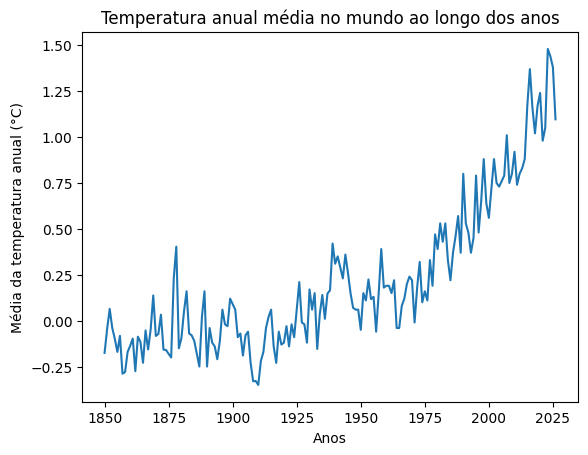

In [ ]:
sns.lineplot(x='year', y='mean', data=df_continental_temp_grouped)
plt.title('Temperatura anual média no mundo ao longo dos anos')
plt.xlabel('Anos')
plt.ylabel('Média da temperatura anual (°C)')

## 2) Junção dos Dados
Vamos unir os DataFrames com base no ano.

In [ ]:
# testando um Outer Join
outer_join = pd.merge(df_global_temp_reset_drop, df_continental_temp_grouped, on='year', how='right')

print("outer Join:")
outer_join

outer Join:


,country,year,iso_code,population,gdp,cement_co2,cement_co2_per_capita,co2,co2_growth_abs,co2_growth_prct,co2_including_luc,co2_including_luc_growth_abs,co2_including_luc_growth_prct,co2_including_luc_per_capita,co2_including_luc_per_gdp,co2_including_luc_per_unit_energy,co2_per_capita,co2_per_gdp,co2_per_unit_energy,coal_co2,coal_co2_per_capita,consumption_co2,consumption_co2_per_capita,consumption_co2_per_gdp,cumulative_cement_co2,cumulative_co2,cumulative_co2_including_luc,cumulative_coal_co2,cumulative_flaring_co2,cumulative_gas_co2,cumulative_luc_co2,cumulative_oil_co2,cumulative_other_co2,energy_per_capita,energy_per_gdp,flaring_co2,flaring_co2_per_capita,gas_co2,gas_co2_per_capita,...,land_use_change_co2,land_use_change_co2_per_capita,methane,methane_per_capita,nitrous_oxide,nitrous_oxide_per_capita,oil_co2,oil_co2_per_capita,other_co2_per_capita,other_industry_co2,primary_energy_consumption,share_global_cement_co2,share_global_co2,share_global_co2_including_luc,share_global_coal_co2,share_global_cumulative_cement_co2,share_global_cumulative_co2,share_global_cumulative_co2_including_luc,share_global_cumulative_coal_co2,share_global_cumulative_flaring_co2,share_global_cumulative_gas_co2,share_global_cumulative_luc_co2,share_global_cumulative_oil_co2,share_global_cumulative_other_co2,share_global_flaring_co2,share_global_gas_co2,share_global_luc_co2,share_global_oil_co2,share_global_other_co2,share_of_temperature_change_from_ghg,temperature_change_from_ch4,temperature_change_from_co2,temperature_change_from_ghg,temperature_change_from_n2o,total_ghg,total_ghg_excluding_lucf,trade_co2,trade_co2_share,mean
0,Afghanistan,1850,AFG,3752993.0,NaN,0.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000,NaN,NaN,NaN,NaN,NaN,2.827,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.827,0.753,3.595,0.958,0.223,0.060,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.104,NaN,NaN,NaN,NaN,0.104,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.545,0.629,NaN,NaN,-0.1755
1,Africa,1850,NaN,112301163.0,NaN,0.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000,NaN,NaN,NaN,NaN,NaN,428.479,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,428.479,3.819,71.470,0.636,10.865,0.097,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.788,NaN,NaN,NaN,NaN,15.788,NaN,NaN,NaN,NaN,NaN,NaN,NaN,362.797,20.206,NaN,NaN,-0.1755
2,Africa (GCP),1850,NaN,NaN,NaN,NaN,NaN,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.1755
3,Albania,1850,ALB,501490.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.192,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.192,2.378,0.600,1.196,0.044,0.088,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.044,NaN,NaN,NaN,NaN,0.044,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.468,0.273,NaN,NaN,-0.1755
4,Algeria,1850,DZA,2852648.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.347,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.347,0.472,1.309,0.459,0.087,0.030,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.050,NaN,NaN,NaN,NaN,0.050,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.789,0.538,NaN,NaN,-0.1755
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44167,Yemen,2024,YEM,40583173.0,NaN,0.788,0.019,10.123,-0.018,-0.178,10.328,0.074,0.717,0.254,NaN,167.662,0.249,NaN,164.337,0.509,0.013,NaN,NaN,NaN,29.042,708.031,744.745,5.634,46.056,12.566,-16.931,614.734,NaN,1517.856,NaN,0.704,0.017,0.039,0.001,...,0.205,0.005

Vou fazer um Inner Join, porque acredito que seja a melhor opção

In [ ]:
# Inner Join

# nesse caso estamos recebendo um DataFrame que inclui os dados dos anos 1850 até 2024
# Desse modo, estamos excluindo os anos antes de 1850, 2025 e 2026
df_combined = pd.merge(df_global_temp_reset_drop, df_continental_temp_grouped, on='year', how='inner')

print("Inner Join:")
df_combined

Inner Join:


,country,year,iso_code,population,gdp,cement_co2,cement_co2_per_capita,co2,co2_growth_abs,co2_growth_prct,co2_including_luc,co2_including_luc_growth_abs,co2_including_luc_growth_prct,co2_including_luc_per_capita,co2_including_luc_per_gdp,co2_including_luc_per_unit_energy,co2_per_capita,co2_per_gdp,co2_per_unit_energy,coal_co2,coal_co2_per_capita,consumption_co2,consumption_co2_per_capita,consumption_co2_per_gdp,cumulative_cement_co2,cumulative_co2,cumulative_co2_including_luc,cumulative_coal_co2,cumulative_flaring_co2,cumulative_gas_co2,cumulative_luc_co2,cumulative_oil_co2,cumulative_other_co2,energy_per_capita,energy_per_gdp,flaring_co2,flaring_co2_per_capita,gas_co2,gas_co2_per_capita,...,land_use_change_co2,land_use_change_co2_per_capita,methane,methane_per_capita,nitrous_oxide,nitrous_oxide_per_capita,oil_co2,oil_co2_per_capita,other_co2_per_capita,other_industry_co2,primary_energy_consumption,share_global_cement_co2,share_global_co2,share_global_co2_including_luc,share_global_coal_co2,share_global_cumulative_cement_co2,share_global_cumulative_co2,share_global_cumulative_co2_including_luc,share_global_cumulative_coal_co2,share_global_cumulative_flaring_co2,share_global_cumulative_gas_co2,share_global_cumulative_luc_co2,share_global_cumulative_oil_co2,share_global_cumulative_other_co2,share_global_flaring_co2,share_global_gas_co2,share_global_luc_co2,share_global_oil_co2,share_global_other_co2,share_of_temperature_change_from_ghg,temperature_change_from_ch4,temperature_change_from_co2,temperature_change_from_ghg,temperature_change_from_n2o,total_ghg,total_ghg_excluding_lucf,trade_co2,trade_co2_share,mean
0,Afghanistan,1850,AFG,3.752993e+06,NaN,0.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000,NaN,NaN,NaN,NaN,NaN,2.827,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.827,0.753,3.595,0.958,0.223,0.060,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.104,NaN,NaN,NaN,NaN,0.104,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.545,0.629,NaN,NaN,-0.1755
1,Africa,1850,NaN,1.123012e+08,NaN,0.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000,NaN,NaN,NaN,NaN,NaN,428.479,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,428.479,3.819,71.470,0.636,10.865,0.097,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.788,NaN,NaN,NaN,NaN,15.788,NaN,NaN,NaN,NaN,NaN,NaN,NaN,362.797,20.206,NaN,NaN,-0.1755
2,Africa (GCP),1850,NaN,NaN,NaN,NaN,NaN,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.1755
3,Albania,1850,ALB,5.014900e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.192,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.192,2.378,0.600,1.196,0.044,0.088,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.044,NaN,NaN,NaN,NaN,0.044,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.468,0.273,NaN,NaN,-0.1755
4,Algeria,1850,DZA,2.852648e+06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.347,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.347,0.472,1.309,0.459,0.087,0.030,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.050,NaN,NaN,NaN,NaN,0.050,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.789,0.538,NaN,NaN,-0.1755
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44165,Wallis and Futuna,2024,WLF,1.130300e+04,NaN,0.000,0.000,0.031,0.001,4.573,NaN,NaN,NaN,NaN,NaN,NaN,2.699,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000,0.866,NaN,NaN,0.000,NaN,NaN,0.866,NaN,NaN,NaN,0.000,0.000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.031,2.699,Na

In [ ]:
# removendo as colunas que mostram dados demográficos de cada país
df_combined.drop(columns=['iso_code', 'gdp'], inplace=True)

# Filtrando apenas os registros onde 'country' é 'World'
# estou fazendo isso porque quero obter o total de co2 no mundo em cada ano registrado.
df_world = df_combined[df_combined['country'] == 'World'].reset_index(drop=True)
#df_world = df_world.drop(columns='country')
# não vou remover a coluna 'country' porque ela vai me ajudar a pivotar o dataset mais pra frente

df_world.head()

,country,year,population,cement_co2,cement_co2_per_capita,co2,co2_growth_abs,co2_growth_prct,co2_including_luc,co2_including_luc_growth_abs,co2_including_luc_growth_prct,co2_including_luc_per_capita,co2_including_luc_per_gdp,co2_including_luc_per_unit_energy,co2_per_capita,co2_per_gdp,co2_per_unit_energy,coal_co2,coal_co2_per_capita,consumption_co2,consumption_co2_per_capita,consumption_co2_per_gdp,cumulative_cement_co2,cumulative_co2,cumulative_co2_including_luc,cumulative_coal_co2,cumulative_flaring_co2,cumulative_gas_co2,cumulative_luc_co2,cumulative_oil_co2,cumulative_other_co2,energy_per_capita,energy_per_gdp,flaring_co2,flaring_co2_per_capita,gas_co2,gas_co2_per_capita,ghg_excluding_lucf_per_capita,ghg_per_capita,land_use_change_co2,land_use_change_co2_per_capita,methane,methane_per_capita,nitrous_oxide,nitrous_oxide_per_capita,oil_co2,oil_co2_per_capita,other_co2_per_capita,other_industry_co2,primary_energy_consumption,share_global_cement_co2,share_global_co2,share_global_co2_including_luc,share_global_coal_co2,share_global_cumulative_cement_co2,share_global_cumulative_co2,share_global_cumulative_co2_including_luc,share_global_cumulative_coal_co2,share_global_cumulative_flaring_co2,share_global_cumulative_gas_co2,share_global_cumulative_luc_co2,share_global_cumulative_oil_co2,share_global_cumulative_other_co2,share_global_flaring_co2,share_global_gas_co2,share_global_luc_co2,share_global_oil_co2,share_global_other_co2,share_of_temperature_change_from_ghg,temperature_change_from_ch4,temperature_change_from_co2,temperature_change_from_ghg,temperature_change_from_n2o,total_ghg,total_ghg_excluding_lucf,trade_co2,trade_co2_share,mean
0,World,1850,1.275603e+09,NaN,NaN,196.848,11.800,6.376,2910.870,NaN,NaN,2.282,1.882,NaN,0.154,0.127,NaN,196.848,0.154,NaN,NaN,NaN,NaN,4769.853,2910.870,4769.853,NaN,NaN,2714.022,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.535,3.366,2714.022,2.128,1239.419,0.972,143.746,0.113,NaN,NaN,0.0,0.0,NaN,NaN,100.0,100.0,100.0,NaN,100.0,100.0,100.0,NaN,NaN,100.0,NaN,NaN,NaN,NaN,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4293.311,682.352,NaN,NaN,-0.1755
1,World,1851,1.278768e+09,NaN,NaN,198.779,1.931,0.981,3019.546,108.676,3.733,2.361,NaN,NaN,0.155,NaN,NaN,198.779,0.155,NaN,NaN,NaN,NaN,4968.631,5930.416,4968.631,NaN,NaN,5534.790,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.536,3.448,2820.767,2.206,1244.062,0.973,146.325,0.114,NaN,NaN,0.0,0.0,NaN,NaN,100.0,100.0,100.0,NaN,100.0,100.0,100.0,NaN,NaN,100.0,NaN,NaN,NaN,NaN,100.0,NaN,NaN,100.0,0.000,0.001,0.002,0.0,4409.168,685.485,NaN,NaN,-0.0453
2,World,1852,1.281158e+09,NaN,NaN,207.595,8.817,4.435,3124.945,105.399,3.491,2.439,NaN,NaN,0.162,NaN,NaN,207.595,0.162,NaN,NaN,NaN,NaN,5176.226,9055.361,5176.226,NaN,NaN,8452.140,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.544,3.531,2917.350,2.277,1250.699,0.976,148.849,0.116,NaN,NaN,0.0,0.0,NaN,NaN,100.0,100.0,100.0,NaN,100.0,100.0,100.0,NaN,NaN,100.0,NaN,NaN,NaN,NaN,100.0,NaN,NaN,100.0,0.001,0.003,0.004,0.0,4523.711,697.492,NaN,NaN,0.0643
3,World,1853,1.282782e+09,NaN,NaN,217.237,9.642,4.645,3152.687,27.742,0.888,2.458,NaN,NaN,0.169,NaN,NaN,217.237,0.169,NaN,NaN,NaN,NaN,5393.463,12208.048,5393.463,NaN,NaN,11387.590,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.554,3.556,2935.450,2.288,1258.197,0.981,151.281,0.118,NaN,NaN,0.0,0.0,NaN,NaN,100.0,100.0,100.0,NaN,100.0,100.0,100.0,NaN,NaN,100.0,NaN,NaN,NaN,NaN,100.0,NaN,NaN,100.0,0.001,0.004,0.006,0.0,4561.398,711.177,NaN,NaN,-0.0398
4,World,1854,1.284515e+09,NaN,NaN,255.039,37.802,17.401,3230.597,77.910,2.471,2.515,NaN,NaN,0.199,NaN,NaN,255.039,0.199,NaN,NaN,NaN,NaN,5648.502,15438.646,5648.502,NaN,NaN,14363.148,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.590,3.623,2975.559,2.316,1270.693,0.989,153.588,0.120,NaN,NaN,0.0,0.0,NaN,NaN,100.0,100.0,100.0,NaN,100.0,100.0,100.0,NaN,NaN,100.0,NaN,NaN,NaN,NaN,100.0,NaN,NaN,100.0,0.002,0.006,0.008,0.0,4653.988,758.008,NaN,NaN,-0.0993


In [ ]:
df_world.shape
# agora o DataFrame tem 175 linhas e 78 colunas!

(175, 78)

In [ ]:
columns_list = df_world.columns.to_list()

share_columns_list = []

for column in columns_list:
  if 'share' in column:
    share_columns_list.append(column)

print(share_columns_list)
print('Número de colunas que contém a substring share: ', len(share_columns_list))

['share_global_cement_co2', 'share_global_co2', 'share_global_co2_including_luc', 'share_global_coal_co2', 'share_global_cumulative_cement_co2', 'share_global_cumulative_co2', 'share_global_cumulative_co2_including_luc', 'share_global_cumulative_coal_co2', 'share_global_cumulative_flaring_co2', 'share_global_cumulative_gas_co2', 'share_global_cumulative_luc_co2', 'share_global_cumulative_oil_co2', 'share_global_cumulative_other_co2', 'share_global_flaring_co2', 'share_global_gas_co2', 'share_global_luc_co2', 'share_global_oil_co2', 'share_global_other_co2', 'share_of_temperature_change_from_ghg', 'trade_co2_share']
Número de colunas que contém a substring share:  20


In [ ]:
# removendo as colunas que representam um share (porcentagem)
df_world = df_world.drop(columns=share_columns_list)
df_world.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175 entries, 0 to 174
Data columns (total 58 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   country                            175 non-null    object 
 1   year                               175 non-null    int64  
 2   population                         175 non-null    float64
 3   cement_co2                         145 non-null    float64
 4   cement_co2_per_capita              145 non-null    float64
 5   co2                                175 non-null    float64
 6   co2_growth_abs                     175 non-null    float64
 7   co2_growth_prct                    175 non-null    float64
 8   co2_including_luc                  175 non-null    float64
 9   co2_including_luc_growth_abs       174 non-null    float64
 10  co2_including_luc_growth_prct      174 non-null    float64
 11  co2_including_luc_per_capita       175 non-null    float64

In [ ]:
df_world.isnull().sum()

,0
country,0
year,0
population,0
cement_co2,30
cement_co2_per_capita,30
co2,0
co2_growth_abs,0
co2_growth_prct,0
co2_including_luc,0
co2_including_luc_growth_abs,1


- Tratando os valores nulos

In [ ]:
df_world = df_world.drop(columns=['co2_including_luc_per_gdp', 'co2_including_luc_per_unit_energy', 'co2_per_gdp',
                       'co2_per_unit_energy', 'consumption_co2', 'consumption_co2_per_capita',
                       'consumption_co2_per_gdp', 'cumulative_flaring_co2', 'energy_per_capita',
                       'energy_per_gdp', 'flaring_co2', 'flaring_co2_per_capita',
                       'primary_energy_consumption', 'trade_co2'])

# tudo o que for antes disso será preenchido com 0 (pois nao havia producao industrial tao forte)
ano_corte = 1900

# 1. Nos anos anteriores ao ano de corte, preenche os nulos com 0
mascara_antigos = df_world['year'] < ano_corte
df_world.loc[mascara_antigos] = df_world.loc[mascara_antigos].fillna(0)

# o resto das colunas eu vou preencher com a mediana
# 2. Nos anos restantes (de 1900 em diante), preenche os nulos restantes com a mediana
df_world = df_world.fillna(df_world.median(numeric_only=True))

In [ ]:
df_world.isnull().sum()
# agora nao tem mais nenhum valor nulo

,0
country,0
year,0
population,0
cement_co2,0
cement_co2_per_capita,0
co2,0
co2_growth_abs,0
co2_growth_prct,0
co2_including_luc,0
co2_including_luc_growth_abs,0


In [ ]:
df_world.head()

,country,year,population,cement_co2,cement_co2_per_capita,co2,co2_growth_abs,co2_growth_prct,co2_including_luc,co2_including_luc_growth_abs,co2_including_luc_growth_prct,co2_including_luc_per_capita,co2_per_capita,coal_co2,coal_co2_per_capita,cumulative_cement_co2,cumulative_co2,cumulative_co2_including_luc,cumulative_coal_co2,cumulative_gas_co2,cumulative_luc_co2,cumulative_oil_co2,cumulative_other_co2,gas_co2,gas_co2_per_capita,ghg_excluding_lucf_per_capita,ghg_per_capita,land_use_change_co2,land_use_change_co2_per_capita,methane,methane_per_capita,nitrous_oxide,nitrous_oxide_per_capita,oil_co2,oil_co2_per_capita,other_co2_per_capita,other_industry_co2,temperature_change_from_ch4,temperature_change_from_co2,temperature_change_from_ghg,temperature_change_from_n2o,total_ghg,total_ghg_excluding_lucf,mean
0,World,1850,1.275603e+09,0.0,0.0,196.848,11.800,6.376,2910.870,0.000,0.000,2.282,0.154,196.848,0.154,0.0,4769.853,2910.870,4769.853,0.0,2714.022,0.0,0.0,0.0,0.0,0.535,3.366,2714.022,2.128,1239.419,0.972,143.746,0.113,0.0,0.0,0.0,0.0,0.000,0.000,0.000,0.0,4293.311,682.352,-0.1755
1,World,1851,1.278768e+09,0.0,0.0,198.779,1.931,0.981,3019.546,108.676,3.733,2.361,0.155,198.779,0.155,0.0,4968.631,5930.416,4968.631,0.0,5534.790,0.0,0.0,0.0,0.0,0.536,3.448,2820.767,2.206,1244.062,0.973,146.325,0.114,0.0,0.0,0.0,0.0,0.000,0.001,0.002,0.0,4409.168,685.485,-0.0453
2,World,1852,1.281158e+09,0.0,0.0,207.595,8.817,4.435,3124.945,105.399,3.491,2.439,0.162,207.595,0.162,0.0,5176.226,9055.361,5176.226,0.0,8452.140,0.0,0.0,0.0,0.0,0.544,3.531,2917.350,2.277,1250.699,0.976,148.849,0.116,0.0,0.0,0.0,0.0,0.001,0.003,0.004,0.0,4523.711,697.492,0.0643
3,World,1853,1.282782e+09,0.0,0.0,217.237,9.642,4.645,3152.687,27.742,0.888,2.458,0.169,217.237,0.169,0.0,5393.463,12208.048,5393.463,0.0,11387.590,0.0,0.0,0.0,0.0,0.554,3.556,2935.450,2.288,1258.197,0.981,151.281,0.118,0.0,0.0,0.0,0.0,0.001,0.004,0.006,0.0,4561.398,711.177,-0.0398
4,World,1854,1.284515e+09,0.0,0.0,255.039,37.802,17.401,3230.597,77.910,2.471,2.515,0.199,255.039,0.199,0.0,5648.502,15438.646,5648.502,0.0,14363.148,0.0,0.0,0.0,0.0,0.590,3.623,2975.559,2.316,1270.693,0.989,153.588,0.120,0.0,0.0,0.0,0.0,0.002,0.006,0.008,0.0,4653.988,758.008,-0.0993


## 3) Recombinação dos Dados
Vamos calcular a correlação entre as temperaturas médias e os níveis de CO2.

In [ ]:
# vou buscar no dicionário todas as definicioes das colunas envolvendo CO2
filt_co2 = data_dictionary.index.str.contains('co2', na=False)
data_dictionary.loc[filt_co2]

,title,description,unit,source
column,,,,
cement_co2,Annual CO₂ emissions from cement,Annual emissions of carbon dioxide (CO₂) from ...,million tonnes (Mt),Global Carbon Budget (2025) [https://globalcar...
cement_co2_per_capita,Annual CO₂ emissions from cement (per capita),Annual emissions of carbon dioxide (CO₂) from ...,tonnes per person (t/person),Global Carbon Budget (2025) [https://globalcar...
co2,Annual CO₂ emissions,Annual total emissions of carbon dioxide (CO₂)...,million tonnes (Mt),Global Carbon Budget (2025) [https://globalcar...
co2_growth_abs,Annual CO₂ emissions growth (abs),Annual growth in total emissions of carbon dio...,million tonnes (Mt),Global Carbon Budget (2025) [https://globalcar...
co2_growth_prct,Annual CO₂ emissions growth (%),Annual percentage growth in total emissions of...,%,Global Carbon Budget (2025) [https://globalcar...
co2_including_luc,Annual CO₂ emissions including land-use change,Annual total emissions of carbon dioxide (CO₂)...,million tonnes (Mt),Global Carbon Budget (2025) [https://globalcar...
co2_including_luc_growth_abs,Growth rate of emissions including land-use ch...,Annual growth in total emissions of carbon dio...,million tonnes (Mt),Global Carbon Budget (2025) [https://globalcar...
co2_including_luc_growth_prct,Growth rate of emissions including land-use ch...,Annual percentage growth in total emissions of...,%,Global Carbon Budget (2025) [https://globalcar...
co2_including_luc_per_capita,Annual CO₂ emissions including land-use change...,"Annual emissions of carbon dioxide (CO₂), incl...",tonnes per person (t/person),Global Carbon Budget (2025) [https://globalcar...


In [ ]:
lista_co2_correlacao = []

for column in df_world.columns.to_list():
  if 'co2' in column:
    lista_co2_correlacao.append(column)

lista_co2_correlacao.append('mean')
lista_co2_correlacao.append('year')
lista_co2_correlacao.append('population')
print(lista_co2_correlacao)

['cement_co2', 'cement_co2_per_capita', 'co2', 'co2_growth_abs', 'co2_growth_prct', 'co2_including_luc', 'co2_including_luc_growth_abs', 'co2_including_luc_growth_prct', 'co2_including_luc_per_capita', 'co2_per_capita', 'coal_co2', 'coal_co2_per_capita', 'cumulative_cement_co2', 'cumulative_co2', 'cumulative_co2_including_luc', 'cumulative_coal_co2', 'cumulative_gas_co2', 'cumulative_luc_co2', 'cumulative_oil_co2', 'cumulative_other_co2', 'gas_co2', 'gas_co2_per_capita', 'land_use_change_co2', 'land_use_change_co2_per_capita', 'oil_co2', 'oil_co2_per_capita', 'other_co2_per_capita', 'other_industry_co2', 'temperature_change_from_co2', 'mean', 'year', 'population']


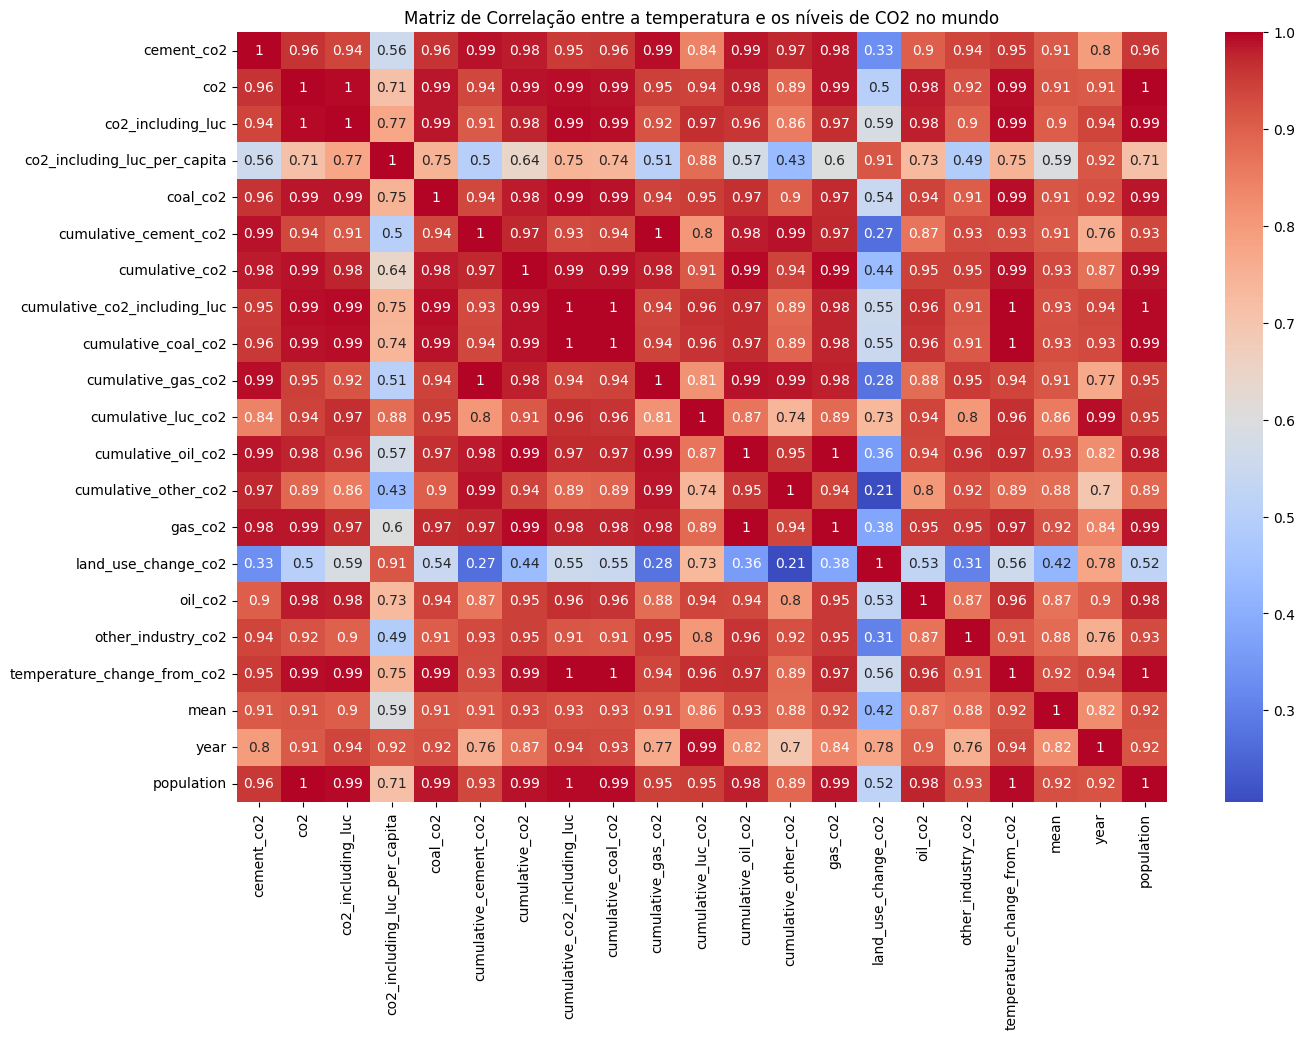

In [ ]:
# calcular e visualizar matriz de correlacao entre a temperatura media e os niveis de CO2

plt.figure(figsize=(15, 10))
correlacao = df_world[['cement_co2', 'co2', 'co2_including_luc', 'co2_including_luc_per_capita',
                        'coal_co2', 'cumulative_cement_co2', 'cumulative_co2', 'cumulative_co2_including_luc',
                        'cumulative_coal_co2', 'cumulative_gas_co2', 'cumulative_luc_co2', 'cumulative_oil_co2',
                        'cumulative_other_co2', 'gas_co2', 'land_use_change_co2', 'oil_co2', 'other_industry_co2',
                        'temperature_change_from_co2', 'mean', 'year', 'population']].corr()
sns.heatmap(correlacao, annot=True, cmap='coolwarm')
plt.title('Matriz de Correlação entre a temperatura e os níveis de CO2 no mundo')
plt.show()

## 4) Reformatação dos Dados
Vamos reformular os dados para mostrar as temperaturas médias em formato largo, com anos como colunas.

In [ ]:
df_wide = df_world.pivot(
    index='country',
    columns='year',      # A coluna cujos valores virarão o cabeçalho das novas colunas
    values='mean'        # A coluna com os valores numéricos que preencherão a tabela
)

df_wide.columns.name = None   # remove o nome 'year' do índice

In [ ]:
df_wide

,1850,1851,1852,1853,1854,1855,1856,1857,1858,1859,1860,1861,1862,1863,1864,1865,1866,1867,1868,1869,1870,1871,1872,1873,1874,1875,1876,1877,1878,1879,1880,1881,1882,1883,1884,1885,1886,1887,1888,...,1986,1987,1988,1989,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
country,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
World,-0.1755,-0.0453,0.0643,-0.0398,-0.0993,-0.1703,-0.0828,-0.2888,-0.2801,-0.1699,-0.1366,-0.0976,-0.2752,-0.0872,-0.1159,-0.2297,-0.0532,-0.1567,-0.0465,0.1374,-0.0832,-0.0727,0.0327,-0.1578,-0.1597,-0.1809,-0.2006,0.2297,0.403,-0.1503,-0.0949,0.05,0.16,-0.07,-0.08,-0.11,-0.18,-0.25,0.02,...,0.37,0.46,0.57,0.37,0.8,0.53,0.48,0.37,0.45,0.79,0.48,0.65,0.88,0.64,0.56,0.72,0.88,0.75,0.73,0.76,0.79,1.01,0.75,0.8,0.92,0.74,0.8,0.83,0.88,1.17,1.37,1.16,1.02,1.17,1.24,0.98,1.05,1.48,1.44


In [ ]:
# 1. Renomeia o valor 'World' no índice para 'Mean Temperature'
df_wide = df_wide.rename(index={'World': 'mean global temperature'})

# 2. Remove o nome do índice ('country')
df_wide.index.name = None

In [ ]:
df_wide

,1850,1851,1852,1853,1854,1855,1856,1857,1858,1859,1860,1861,1862,1863,1864,1865,1866,1867,1868,1869,1870,1871,1872,1873,1874,1875,1876,1877,1878,1879,1880,1881,1882,1883,1884,1885,1886,1887,1888,...,1986,1987,1988,1989,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
mean global temperature,-0.1755,-0.0453,0.0643,-0.0398,-0.0993,-0.1703,-0.0828,-0.2888,-0.2801,-0.1699,-0.1366,-0.0976,-0.2752,-0.0872,-0.1159,-0.2297,-0.0532,-0.1567,-0.0465,0.1374,-0.0832,-0.0727,0.0327,-0.1578,-0.1597,-0.1809,-0.2006,0.2297,0.403,-0.1503,-0.0949,0.05,0.16,-0.07,-0.08,-0.11,-0.18,-0.25,0.02,...,0.37,0.46,0.57,0.37,0.8,0.53,0.48,0.37,0.45,0.79,0.48,0.65,0.88,0.64,0.56,0.72,0.88,0.75,0.73,0.76,0.79,1.01,0.75,0.8,0.92,0.74,0.8,0.83,0.88,1.17,1.37,1.16,1.02,1.17,1.24,0.98,1.05,1.48,1.44


## 5) Faça a análise exploratória dos dados para gerar insights preditivos.

Text(0, 0.5, 'Temperatura média global (°C)')

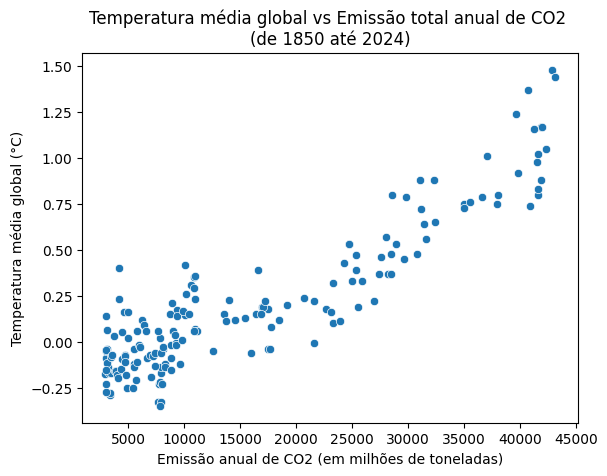

In [ ]:
sns.scatterplot(x='co2_including_luc', y='mean', data=df_world)

plt.title('Temperatura média global vs Emissão total anual de CO2 \n(de 1850 até 2024)')
plt.xlabel('Emissão anual de CO2 (em milhões de toneladas)')
plt.ylabel('Temperatura média global (°C)')

Text(0, 0.5, 'Temperatura média global (°C)')

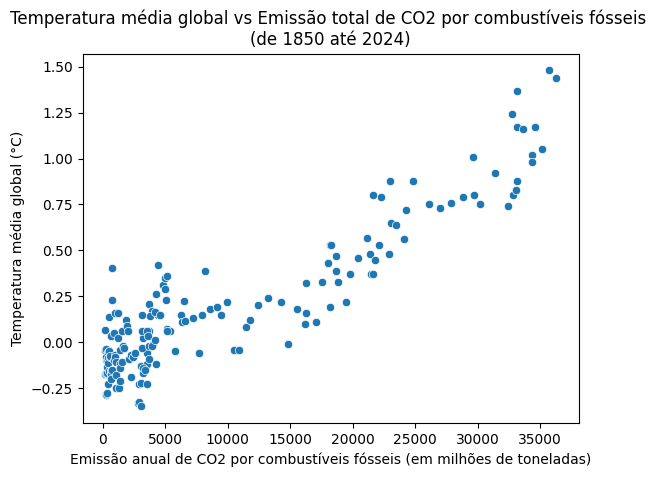

In [ ]:
# criando uma coluna com as emissoes totais causadas por combustiveis fosseis por ano
df_world['fossil_fuels_co2'] = df_world['coal_co2'] + df_world['gas_co2'] + df_world['oil_co2']

# relacionando essa coluna com a Aumento na temperatura global
sns.scatterplot(x='fossil_fuels_co2', y='mean', data=df_world)

plt.title('Temperatura média global vs Emissão total de CO2 por combustíveis fósseis \n(de 1850 até 2024)')
plt.xlabel('Emissão anual de CO2 por combustíveis fósseis (em milhões de toneladas)')
plt.ylabel('Temperatura média global (°C)')

Text(0, 0.5, 'Emissão de CO2 (em milhões de toneladas)')

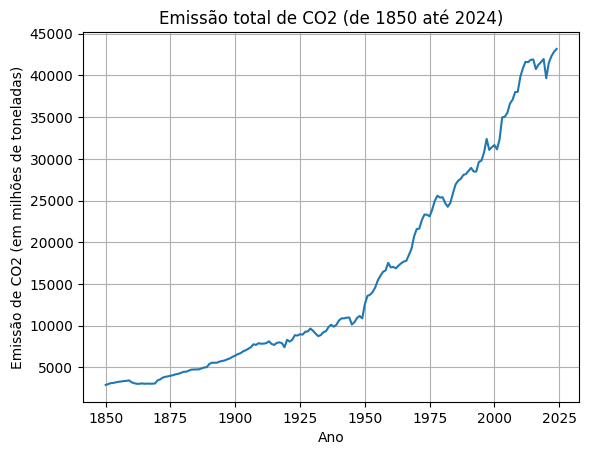

In [ ]:
sns.lineplot(x='year', y='co2_including_luc', data=df_world)

plt.grid(True)
plt.title('Emissão total de CO2 (de 1850 até 2024)')
plt.xlabel('Ano')
plt.ylabel('Emissão de CO2 (em milhões de toneladas)')

Insights:

- Ao comparar o CO2 total com o CO2 proveniente de combustíveis fósseis, a semelhança quase perfeita entre os gráficos demonstra empiricamente que a queima de combustíveis fósseis é o principal motor do aumento do CO2 na atmosfera e, consequentemente, do aquecimento global registrado nas últimas décadas.

Insights preditivos:
- Com base na inclinação observada no gráfico de dispersão, estima-se que a cada 10.000 milhões de toneladas de CO2 fóssil emitidas anualmente, a anomalia de temperatura média global sofra um acréscimo aproximado de +0,3 °C
- Ao longo de todo o tempo registrado (1850 até 2024), a emissão de CO2 apenas apresentou a tendência de crescimento e, segundo o gráfico de linha, provavelmente continuará crescendo pelos próximos anos porque até no último ponto do gráfico a reta estava em rota de subida.

Text(0, 0.5, 'Emissão de CO2 por por mudança no uso da terra (em milhões de toneladas)')

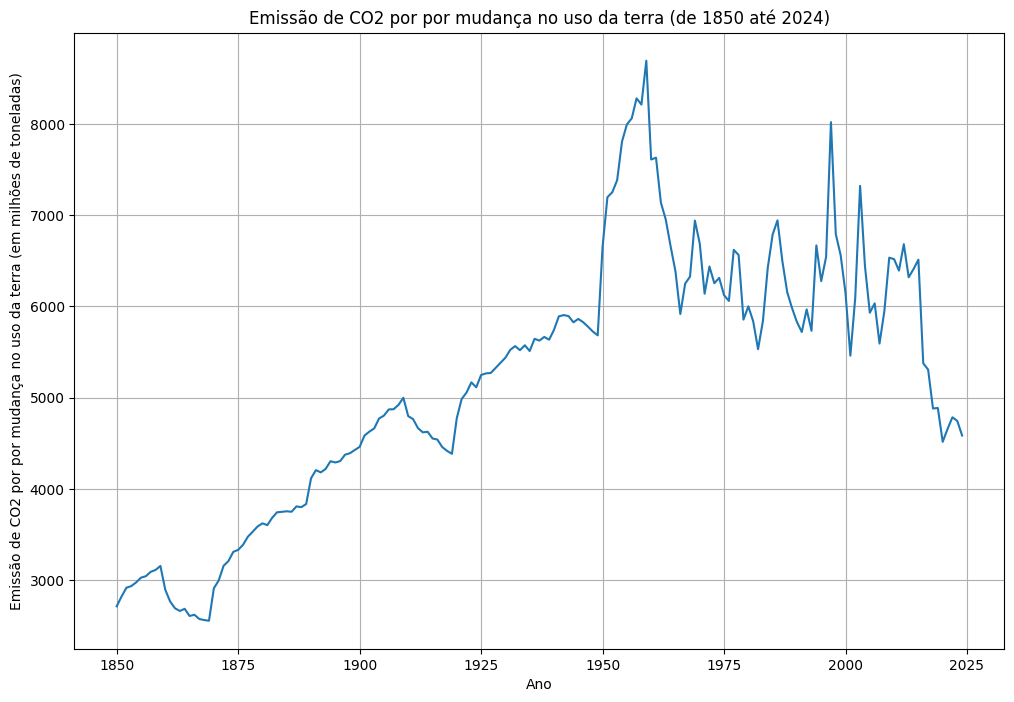

In [ ]:
plt.figure(figsize=(12, 8))
sns.lineplot(x='year', y='land_use_change_co2', data=df_world)

plt.grid(True)
plt.title('Emissão de CO2 por por mudança no uso da terra (de 1850 até 2024)')
plt.xlabel('Ano')
plt.ylabel('Emissão de CO2 por por mudança no uso da terra (em milhões de toneladas)')

Insights:
- A emissão por mudança no uso da terra apresentou tendência de crescimento até atingir o maior pico em meados da década de 1950. Depois disso, passou a diminuir desde então.
- Mesmo com muito ruído (altos e baixos), esse tipo de emissão passou a diminuir no geral, atingindo em 2024 a mesma quantidade que foi registrada em 1900 e também no início da década de 1920.

Insights preditivos:
- Se a taxa de redução da emissão de CO2 por mudança no uso da terra mantiver a tendência descendente iniciada no meio dos anos 50, essa fonte terá cada vez menos influência no efeito estufa e no aquecimento global nas próximas décadas.

Text(0, 0.5, 'Emissão de CO2 por cimento (em milhões de toneladas)')

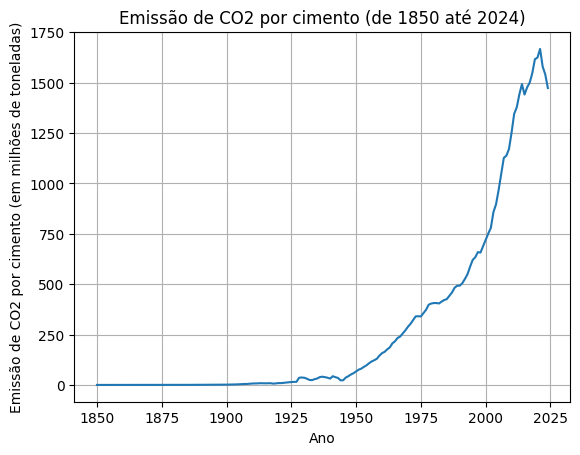

In [ ]:
sns.lineplot(x='year', y='cement_co2', data=df_world)

plt.grid(True)
plt.title('Emissão de CO2 por cimento (de 1850 até 2024)')
plt.xlabel('Ano')
plt.ylabel('Emissão de CO2 por cimento (em milhões de toneladas)')
# esse tipo de emissão começou a diminuir a partir de 2020

Insights:
- A emissão de CO2 por cimento apresentou um crescimento exponencial desde 1850 até cerca de 2019.
- Depois disso esse tipo de emissão começou a diminuir.

Insights preditivos:
- Caso a retração iniciada em 2020 no setor de cimento se consolide como uma tendência de longo prazo, projeta-se uma desaceleração do ritmo de crescimento do CO2 dessa indústria nas próximas décadas.

Text(0, 0.5, 'Anomalia de Temperatura (°C)')

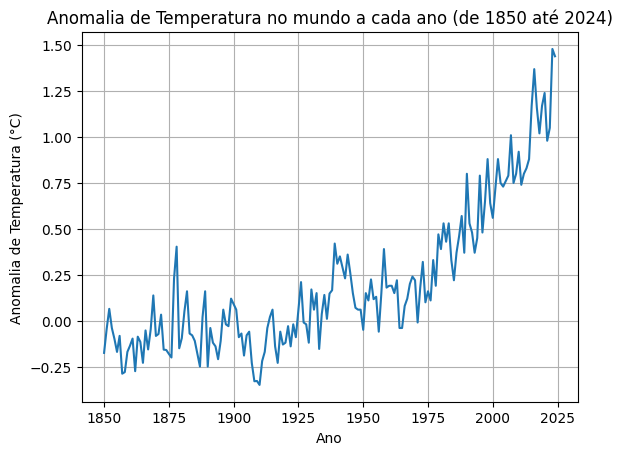

In [ ]:
sns.lineplot(x='year', y='mean', data=df_world)

plt.grid(True)
plt.title('Anomalia de Temperatura no mundo a cada ano (de 1850 até 2024)')
plt.xlabel('Ano')
plt.ylabel('Anomalia de Temperatura (°C)')

Insights:
- A anomalia de temperatura no mundo é irregular, cheia de altos e baixos. Porém, a tendência que prevaleceu depois do início do século XX foi de aumento gradual ao longo dos anos.

Insights preditivos:
- Projetando a taxa de variação da anomalia de temperatura das últimas décadas (1950-2024), a anomalia global ultrapassará a marca crítica de 1,5 °C nos próximos anos se a trajetória atual das emissões se manter.

In [ ]:
# total de emissões de co2
df_world['co2'].sum()

np.float64(1844550.8520000002)

In [ ]:
df_world['fossil_fuels_co2'].sum()

np.float64(1759846.1479999998)

In [ ]:
df_world['other_industry_co2'].sum()

np.float64(14869.410999999998)

### Criando um modelo de regressão linear para prever a média de temperatura global em graus Celsius

- Não era necessário fazer esse modelo, só estou mantendo aqui porque eu já tinha feito antes de esclarecer minha dúvida.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
# essa é a única variável categórica
# removendo ela teremos apenas valores numéricos
df_world.drop(columns=['country'], inplace=True)

In [ ]:
# quero manter apenas uma variável para cada tipo de emissão, remover varíaveis fortemente correlacionadas
linear_regression_columns = ['year', 'population', 'cement_co2', 'co2', 'co2_including_luc', 'co2_per_capita',
                             'coal_co2', 'gas_co2', 'land_use_change_co2',
                             'oil_co2', 'other_industry_co2', 'mean']

In [ ]:
df_linear_regression = df_world[linear_regression_columns]

Definir Variáveis Independentes e Dependentes:

In [ ]:
X = df_linear_regression.drop('mean', axis=1)
y = df_linear_regression['mean']

Dividir os Dados em Conjuntos de Treinamento e Teste

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Criar e Treinar o Modelo de Regressão Linear

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

Prever os Valores e Avaliar o Modelo

In [ ]:
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'R²: {r2}')
# o modelo alcançou aproximadamente 90% de precisão!

R²: 0.9033363155878229


Visualizar os Resultados

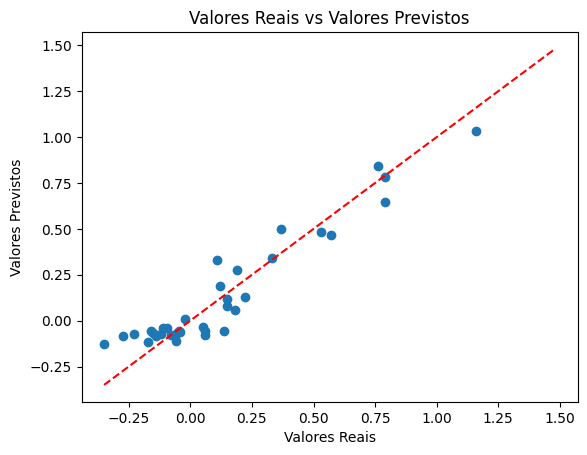

In [ ]:
plt.scatter(y_test, y_pred)
plt.xlabel('Valores Reais')
plt.ylabel('Valores Previstos')
plt.title('Valores Reais vs Valores Previstos')
plt.plot([y.min(), y.max()], [y.min(), y.max()], '--r')
plt.show()

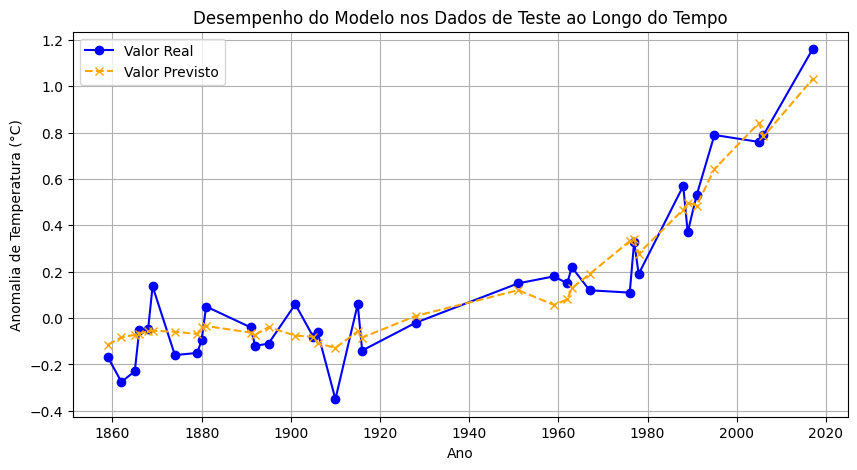

In [ ]:
# Criar um DataFrame organizado pelos anos do conjunto de teste
df_resultado_teste = pd.DataFrame({
    'year': X_test['year'],
    'Real': y_test,
    'Previsto': y_pred
}).sort_values('year')

plt.figure(figsize=(10, 5))
plt.plot(df_resultado_teste['year'], df_resultado_teste['Real'], label='Valor Real', marker='o', color='blue')
plt.plot(df_resultado_teste['year'], df_resultado_teste['Previsto'], label='Valor Previsto', marker='x', linestyle='--', color='orange')

plt.title('Desempenho do Modelo nos Dados de Teste ao Longo do Tempo')
plt.xlabel('Ano')
plt.ylabel('Anomalia de Temperatura (°C)')
plt.legend()
plt.grid(True)
plt.show()

Insights preditivos:

- Antes de cerca de 1910, a anomalia de temperatura se manteve em valores com tendência constante, mesmo com os altos e baixos.
- Após a queda em 1910, ela passou a subir até alcançar o valor de aproximadamente 1,2 °C em 2020.
- O modelo previu corretamente a tendência de aumento da anomalia de temperatura que começou lá em 1910.
- De acordo com a previsão do modelo, a anomalia de temperatura continuará a subir nos próximos anos.